# Endterm Research Project
## Predictive Modelling of Student Grades and Deterministic Target-Score Estimation

**Researcher:** Dauren Shatyrbekov  
**University:** Astana IT University  
**Course:** Research Methods

### Project objective
This notebook implements two separate components:

1. **Grade prediction:** train and compare regression models that predict the final grade (`G3`) from information available earlier (`G1`, `G2`, and student/course characteristics).
2. **Required-score calculator:** calculate the score needed on a remaining assessment to reach a selected target grade.

The prediction experiment uses a real public dataset from the UCI Machine Learning Repository. The calculator is evaluated separately using deterministic test cases. These two components answer different questions and their results must not be mixed.

## 1. Dataset and research questions

**Dataset:** UCI Student Performance (Portuguese secondary-school mathematics and Portuguese language courses).

- The original files contain real student records collected in two Portuguese schools.
- Target: `G3` — final course grade on a 0–20 scale.
- Early academic features: `G1` and `G2` — first- and second-period grades.
- Additional features: study time, absences, failures, family and school characteristics, and other student/course attributes.
- The two course files are combined and a `course` feature is added.

**Research questions**
- RQ1: How accurately can regression models predict the final grade using earlier grades and student characteristics?
- RQ2: Which regression model performs best on the same held-out test set?
- RQ3: How can a deterministic calculator estimate the score required to reach a target?

**Important limitation:** this is a real educational dataset, but it represents Portuguese secondary-school students, not AITU students. Results should therefore not be presented as direct predictions for AITU students. The grade calculator is general mathematics and can be adapted to any course weights.

In [ ]:
import os, zipfile, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Download real data

The notebook downloads the official UCI dataset archive. If the download fails in Colab, upload the ZIP file manually and set `ZIP_PATH` to its location.

In [ ]:
DATA_URL = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"
ZIP_PATH = "/content/student_performance.zip"
EXTRACT_DIR = "/content/student_performance"

if not os.path.exists(ZIP_PATH):
    urllib.request.urlretrieve(DATA_URL, ZIP_PATH)

os.makedirs(EXTRACT_DIR, exist_ok=True)

# Extract the downloaded archive.
with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(EXTRACT_DIR)

# UCI may package the CSV files inside another ZIP archive.
# Extract nested ZIP files recursively so the notebook works with either layout.
checked_archives = set()
while True:
    nested_archives = []
    for root, dirs, files in os.walk(EXTRACT_DIR):
        for filename in files:
            if filename.lower().endswith(".zip"):
                archive_path = os.path.join(root, filename)
                if archive_path not in checked_archives:
                    nested_archives.append(archive_path)

    if not nested_archives:
        break

    for archive_path in nested_archives:
        checked_archives.add(archive_path)
        destination = os.path.join(
            os.path.dirname(archive_path),
            os.path.splitext(os.path.basename(archive_path))[0] + "_extracted"
        )
        os.makedirs(destination, exist_ok=True)
        try:
            with zipfile.ZipFile(archive_path, "r") as nested_zip:
                nested_zip.extractall(destination)
        except zipfile.BadZipFile:
            print("Skipping invalid nested archive:", archive_path)

# Search recursively instead of assuming a fixed folder structure.
csv_paths = {}
for root, dirs, files in os.walk(EXTRACT_DIR):
    for filename in files:
        lower_name = filename.lower()
        if lower_name in ("student-mat.csv", "student-por.csv"):
            csv_paths[lower_name] = os.path.join(root, filename)

if "student-mat.csv" not in csv_paths or "student-por.csv" not in csv_paths:
    print("Files found under extraction directory:")
    for root, dirs, files in os.walk(EXTRACT_DIR):
        for filename in files:
            print(os.path.join(root, filename))
    raise FileNotFoundError(
        "Could not find student-mat.csv and student-por.csv. "
        "Check the extracted archive contents."
    )

math_path = csv_paths["student-mat.csv"]
port_path = csv_paths["student-por.csv"]

math_df = pd.read_csv(math_path, sep=";")
port_df = pd.read_csv(port_path, sep=";")

math_df["course"] = "mathematics"
port_df["course"] = "portuguese"

df = pd.concat([math_df, port_df], ignore_index=True)
print("Mathematics records:", len(math_df))
print("Portuguese records:", len(port_df))
print("Combined dataset shape:", df.shape)
print("Math CSV:", math_path)
print("Portuguese CSV:", port_path)
display(df.head())

Mathematics records: 395
Portuguese records: 649
Combined dataset shape: (1044, 34)
Math CSV: /content/student_performance/student_extracted/student-mat.csv
Portuguese CSV: /content/student_performance/student_extracted/student-por.csv


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,course
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,3,4,1,1,3,6,5,6,6,mathematics
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,3,3,1,1,3,4,5,5,6,mathematics
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,3,2,2,3,3,10,7,8,10,mathematics
3,GP,F,15,U,GT3,T,4,2,health,services,...,2,2,1,1,5,2,15,14,15,mathematics
4,GP,F,16,U,GT3,T,3,3,other,other,...,3,2,1,2,5,4,6,10,10,mathematics


## 3. Initial data inspection

In [ ]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types and non-null counts:")
display(df.info())
print("\nMissing values:")
display(df.isna().sum().sort_values(ascending=False).head(10))
print("\nDescriptive statistics:")
display(df[["G1", "G2", "G3", "studytime", "failures", "absences"]].describe())
print("\nCourse distribution:")
display(df["course"].value_counts())

Dataset shape: (1044, 34)

Column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3', 'course']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1044 entries, 0 to 1043
Data columns (total 34 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      1044 non-null   object
 1   sex         1044 non-null   object
 2   age         1044 non-null   int64 
 3   address     1044 non-null   object
 4   famsize     1044 non-null   object
 5   Pstatus     1044 non-null   object
 6   Medu        1044 non-null   int64 
 7   Fedu        1044 non-null   int64 
 8   Mjob        1044 non-null   object
 9   Fjob        1044 non-null   object
 

None


Missing values:


,0
school,0
sex,0
age,0
address,0
famsize,0
Pstatus,0
Medu,0
Fedu,0
Mjob,0
Fjob,0



Descriptive statistics:


,G1,G2,G3,studytime,failures,absences
count,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000,1044.000000
mean,11.213602,11.246169,11.341954,1.970307,0.264368,4.434866
std,2.983394,3.285071,3.864796,0.834353,0.656142,6.210017
min,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
25%,9.000000,9.000000,10.000000,1.000000,0.000000,0.000000
50%,11.000000,11.000000,11.000000,2.000000,0.000000,2.000000
75%,13.000000,13.000000,14.000000,2.000000,0.000000,6.000000
max,19.000000,19.000000,20.000000,4.000000,3.000000,75.000000



Course distribution:


,count
course,
portuguese,649
mathematics,395


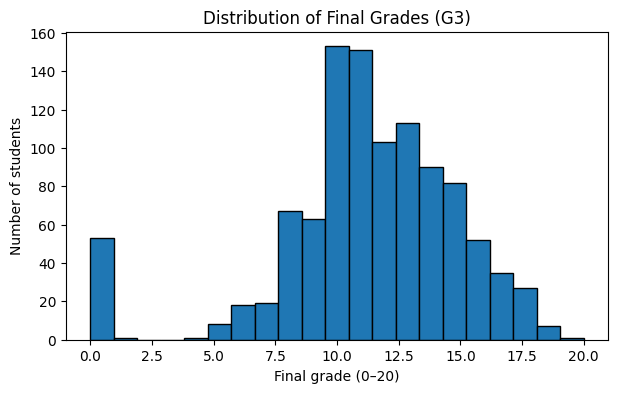

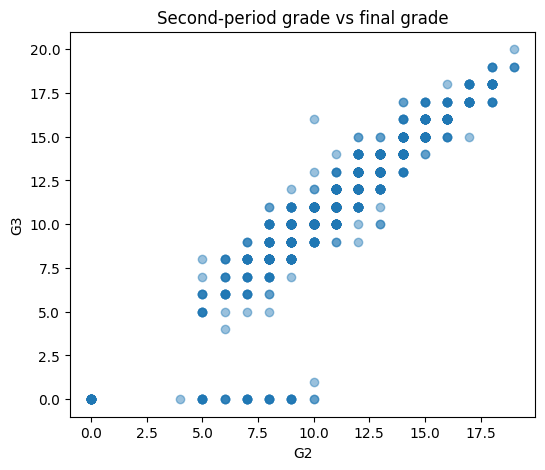

In [ ]:
plt.figure(figsize=(7, 4))
plt.hist(df["G3"], bins=21, edgecolor="black")
plt.title("Distribution of Final Grades (G3)")
plt.xlabel("Final grade (0–20)")
plt.ylabel("Number of students")
plt.show()

plt.figure(figsize=(6, 5))
plt.scatter(df["G2"], df["G3"], alpha=0.45)
plt.title("Second-period grade vs final grade")
plt.xlabel("G2")
plt.ylabel("G3")
plt.show()

## 4. Data preparation and feature selection

`G3` is the prediction target and is removed from the input features. `G1` and `G2` are retained because they are earlier-period grades and are available before the final grade is known. No columns calculated from `G3` are used as predictors.

Categorical variables are one-hot encoded. Numeric variables are imputed and scaled where required. The preprocessing steps are placed inside an ML pipeline to prevent information from the test set leaking into training.

In [ ]:
TARGET = "G3"
X = df.drop(columns=[TARGET]).copy()
y = df[TARGET].copy()

# Remove duplicate rows, if any, before splitting.
combined = pd.concat([X, y.rename(TARGET)], axis=1).drop_duplicates()
X = combined.drop(columns=[TARGET])
y = combined[TARGET]

numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "bool"]).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Training rows: 835
Testing rows: 209
Numeric features: 15
Categorical features: 18


## 5. Model training

Four regression algorithms are compared:

- Linear Regression
- Support Vector Regression (SVR)
- Random Forest Regressor
- Gradient Boosting Regressor

A mean-value baseline and a simple `G2` baseline are also included. All models are evaluated on the same held-out test set.

In [ ]:
models = {
    "Mean baseline": DummyRegressor(strategy="mean"),
    "G2 baseline": None,
    "Linear Regression": LinearRegression(),
    "Support Vector Regression": SVR(C=10, epsilon=0.5, kernel="rbf"),
    "Random Forest": RandomForestRegressor(
        n_estimators=400, min_samples_leaf=2,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200, learning_rate=0.04, max_depth=2,
        random_state=RANDOM_STATE, loss="huber"
    )
}

fitted_models = {}
predictions = {}

# Baseline 1: predict the final grade using the second-period grade directly.
predictions["G2 baseline"] = X_test["G2"].astype(float).values

for name, model in models.items():
    if name == "G2 baseline":
        continue
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])
    pipe.fit(X_train, y_train)
    fitted_models[name] = pipe
    predictions[name] = pipe.predict(X_test)

print("Model training completed.")

Model training completed.


## 6. Evaluation on the test set

Metrics:
- **MAE:** average absolute prediction error, in grade points.
- **RMSE:** gives larger errors more weight.
- **R²:** proportion of target variance explained by the model.

Lower MAE and RMSE are better. Higher R² is generally better. These are actual results calculated from the downloaded dataset after running the notebook.

In [ ]:
results = []
for name, y_pred in predictions.items():
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2": r2_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results).sort_values("MAE").reset_index(drop=True)
display(results_df.round(3))

best_model_name = results_df.iloc[0]["Model"]
print("Best model by MAE:", best_model_name)

,Model,MAE,RMSE,R2
0,G2 baseline,0.847,1.740,0.804
1,Gradient Boosting,0.887,1.743,0.804
2,Random Forest,0.924,1.634,0.827
3,Linear Regression,1.017,1.760,0.800
4,Support Vector Regression,1.130,1.896,0.767
5,Mean baseline,2.939,3.948,-0.008


Best model by MAE: G2 baseline


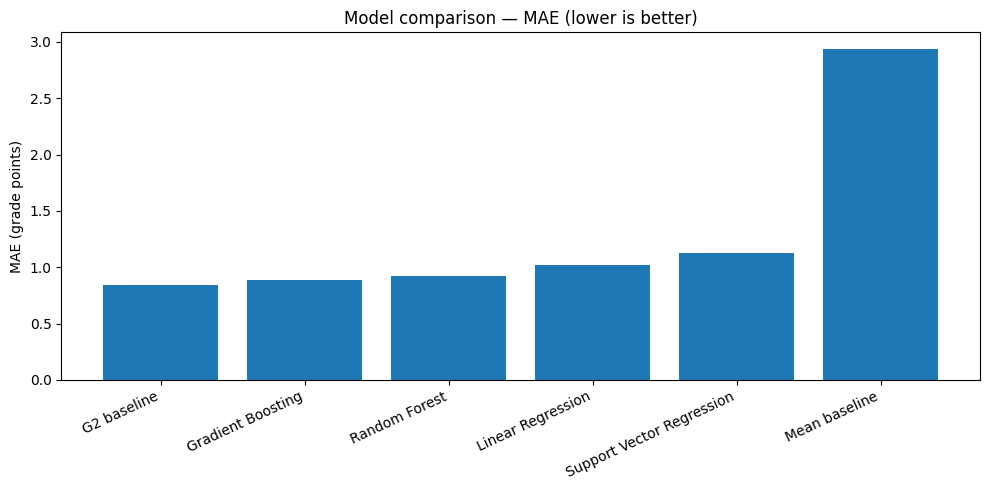

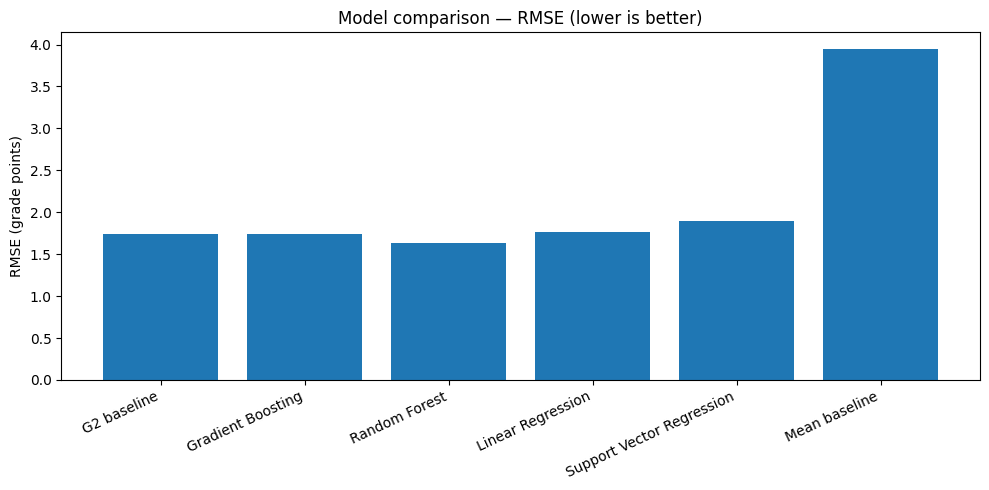

In [ ]:
plt.figure(figsize=(10, 5))
plt.bar(results_df["Model"], results_df["MAE"])
plt.title("Model comparison — MAE (lower is better)")
plt.ylabel("MAE (grade points)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.bar(results_df["Model"], results_df["RMSE"])
plt.title("Model comparison — RMSE (lower is better)")
plt.ylabel("RMSE (grade points)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 7. Actual vs predicted grades

The following chart uses predictions from the best model by test MAE. Points closer to the diagonal represent more accurate predictions.

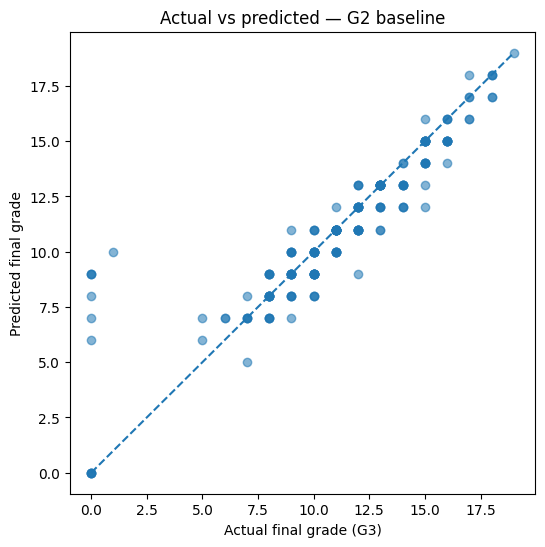

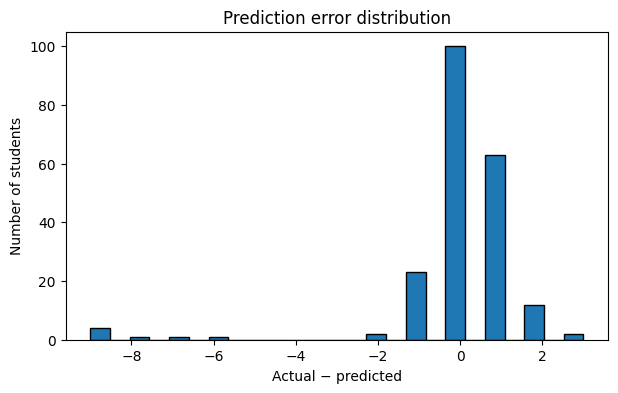

In [ ]:
if best_model_name == "G2 baseline":
    best_predictions = predictions["G2 baseline"]
else:
    best_predictions = predictions[best_model_name]

plt.figure(figsize=(6, 6))
plt.scatter(y_test, best_predictions, alpha=0.55)
low = min(float(y_test.min()), float(np.min(best_predictions)))
high = max(float(y_test.max()), float(np.max(best_predictions)))
plt.plot([low, high], [low, high], linestyle="--")
plt.xlabel("Actual final grade (G3)")
plt.ylabel("Predicted final grade")
plt.title(f"Actual vs predicted — {best_model_name}")
plt.show()

residuals = y_test.values - best_predictions
plt.figure(figsize=(7, 4))
plt.hist(residuals, bins=25, edgecolor="black")
plt.title("Prediction error distribution")
plt.xlabel("Actual − predicted")
plt.ylabel("Number of students")
plt.show()

## 8. Feature importance

Permutation importance measures how much the model's test performance changes when one feature is shuffled. A larger positive value indicates that the feature was more useful to the model. This analysis is shown for the best fitted tree/linear model when available.

,Feature,Importance
31,G2,2.8458
29,absences,0.2016
30,G1,0.0294
32,course,0.0234
2,age,0.0129
7,Fedu,0.0095
23,famrel,0.0085
14,failures,0.0069
28,health,0.0049
11,guardian,0.0022


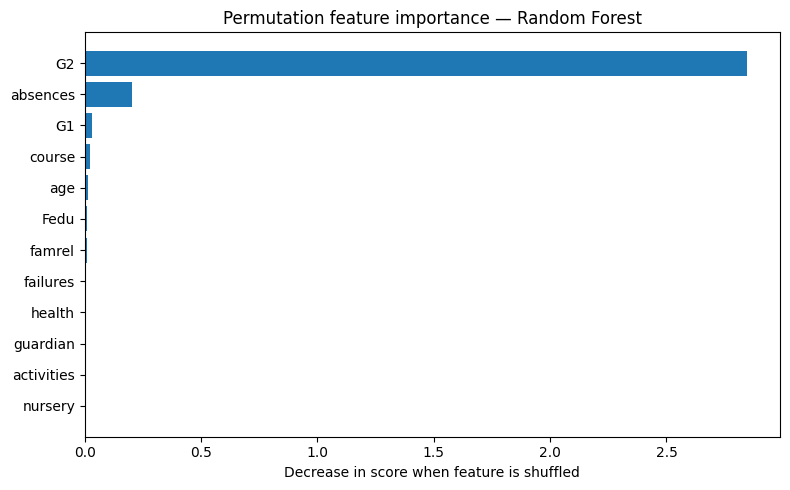

In [ ]:
candidate = "Random Forest" if "Random Forest" in fitted_models else (
    "Gradient Boosting" if "Gradient Boosting" in fitted_models else None
)

if candidate is not None:
    perm = permutation_importance(
        fitted_models[candidate], X_test, y_test,
        n_repeats=8, random_state=RANDOM_STATE,
        scoring="neg_mean_absolute_error", n_jobs=-1
    )
    importance_df = pd.DataFrame({
        "Feature": X_test.columns,
        "Importance": perm.importances_mean
    }).sort_values("Importance", ascending=False).head(12)

    display(importance_df.round(4))
    plt.figure(figsize=(8, 5))
    plt.barh(importance_df["Feature"][::-1], importance_df["Importance"][::-1])
    plt.title(f"Permutation feature importance — {candidate}")
    plt.xlabel("Decrease in score when feature is shuffled")
    plt.tight_layout()
    plt.show()
else:
    print("No suitable fitted model available for permutation importance.")

## 9. Cross-validation check

A single train/test split can depend on the random split. Five-fold cross-validation provides an additional stability check. The pipeline performs preprocessing separately inside each fold.

In [ ]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=250, min_samples_leaf=2,
        random_state=RANDOM_STATE, n_jobs=-1
    ))
])
cv_mae = -cross_val_score(
    cv_model, X, y, cv=cv, scoring="neg_mean_absolute_error", n_jobs=-1
)
print("5-fold CV MAE values:", np.round(cv_mae, 3))
print(f"Mean CV MAE: {cv_mae.mean():.3f}")
print(f"Standard deviation: {cv_mae.std():.3f}")

5-fold CV MAE values: [0.92  0.899 0.966 0.789 0.797]
Mean CV MAE: 0.874
Standard deviation: 0.070


## 10. Deterministic required-score calculator

The calculator is independent of machine learning. If some assessments are completed, their weighted contribution is known. The required score on the remaining assessment is:

\[
S_{required} = \frac{G_{target} - \sum_i S_i W_i}{W_{remaining}}
\]

The result is checked against the valid 0–20 grade range in this dataset example. For a course using a 0–100 scale, change `MAX_SCORE` to 100.

In [ ]:
MAX_SCORE = 20

def required_score(completed_scores, completed_weights, remaining_weight,
                   target, max_score=MAX_SCORE):
    if len(completed_scores) != len(completed_weights):
        raise ValueError("Scores and weights must have the same length.")
    if any(s < 0 or s > max_score for s in completed_scores):
        raise ValueError("Completed scores must be within the allowed range.")
    if any(w < 0 for w in completed_weights) or remaining_weight < 0:
        raise ValueError("Weights cannot be negative.")
    if not np.isclose(sum(completed_weights) + remaining_weight, 1.0):
        raise ValueError("All assessment weights must add up to 1.")
    if target < 0 or target > max_score:
        raise ValueError("Target must be within the allowed grade range.")

    current_contribution = sum(
        s * w for s, w in zip(completed_scores, completed_weights)
    )
    if remaining_weight == 0:
        return {
            "required_score": None,
            "status": "Target reached" if current_contribution >= target else "Impossible"
        }

    needed = (target - current_contribution) / remaining_weight
    if needed <= 0:
        status = "Target already reached"
    elif needed > max_score:
        status = "Impossible"
    else:
        status = "Feasible"

    return {"required_score": round(needed, 2), "status": status}

# Example: completed work is 70% of the course; final exam is 30%.
example = required_score(
    completed_scores=[14, 16],
    completed_weights=[0.30, 0.40],
    remaining_weight=0.30,
    target=15
)
print(example)

{'required_score': 14.67, 'status': 'Feasible'}


## 11. Calculator validation

The calculator is checked against independent expected outcomes, including feasible, already-reached, impossible, and invalid-weight cases. A successful test means the implementation returns the expected status or score.

In [ ]:
tests = [
    # Feasible: (14*0.3 + 16*0.4) = 10.6; (15 - 10.6)/0.3 = 14.6667
    {"args": ([14, 16], [0.30, 0.40], 0.30, 15), "expected_status": "Feasible", "expected_score": 14.67},
    # Target already reached
    {"args": ([18, 18], [0.30, 0.40], 0.30, 12), "expected_status": "Target already reached", "expected_score": 0.0},
    # Impossible
    {"args": ([5, 6], [0.30, 0.40], 0.30, 18), "expected_status": "Impossible", "expected_score": 47.0},
]

passed = 0
for i, t in enumerate(tests, start=1):
    result = required_score(*t["args"])
    status_ok = result["status"] == t["expected_status"]
    if t["expected_score"] == 0.0:
        score_ok = result["required_score"] <= 0
    else:
        score_ok = np.isclose(result["required_score"], t["expected_score"], atol=0.02)
    ok = status_ok and score_ok
    passed += int(ok)
    print(f"Test {i}: {'PASS' if ok else 'FAIL'} | result={result}")

# Invalid weights must be rejected.
try:
    required_score([14], [0.30], 0.30, 15)
    invalid_rejected = False
except ValueError:
    invalid_rejected = True

print("Invalid-weight test:", "PASS" if invalid_rejected else "FAIL")
print(f"Calculator tests passed: {passed + int(invalid_rejected)}/4")

Test 1: PASS | result={'required_score': 14.67, 'status': 'Feasible'}
Test 2: PASS | result={'required_score': -2.0, 'status': 'Target already reached'}
Test 3: PASS | result={'required_score': 47.0, 'status': 'Impossible'}
Invalid-weight test: PASS
Calculator tests passed: 4/4


## 12. Automatically generated research summary

Run this cell after all previous cells. It prints the measured model metrics and calculator test status so that the values can be used in the Endterm presentation. Do not copy results from an unexecuted notebook.

In [ ]:
print("=" * 65)
print("ENDTERM EXPERIMENT SUMMARY")
print("=" * 65)
print(f"Dataset: UCI Student Performance")
print(f"Total records after combining course files: {len(df)}")
print(f"Training records: {len(X_train)} | Test records: {len(X_test)}")
print("\nModel results (sorted by MAE):")
display(results_df.round(3))
print(f"\nBest model by MAE: {best_model_name}")
print(f"Best test MAE: {results_df.iloc[0]['MAE']:.3f}")
print(f"Best test RMSE: {results_df.iloc[0]['RMSE']:.3f}")
print(f"Best test R2: {results_df.iloc[0]['R2']:.3f}")
print("\nCross-validation:")
print(f"Random Forest 5-fold MAE: {cv_mae.mean():.3f} ± {cv_mae.std():.3f}")
print("\nCalculator tests: review the PASS/FAIL output in Section 11.")
print("\nInterpretation: prediction results describe this public dataset only;")
print("they are not validated predictions for AITU students.")

ENDTERM EXPERIMENT SUMMARY
Dataset: UCI Student Performance
Total records after combining course files: 1044
Training records: 835 | Test records: 209

Model results (sorted by MAE):


,Model,MAE,RMSE,R2
0,G2 baseline,0.847,1.740,0.804
1,Gradient Boosting,0.887,1.743,0.804
2,Random Forest,0.924,1.634,0.827
3,Linear Regression,1.017,1.760,0.800
4,Support Vector Regression,1.130,1.896,0.767
5,Mean baseline,2.939,3.948,-0.008



Best model by MAE: G2 baseline
Best test MAE: 0.847
Best test RMSE: 1.740
Best test R2: 0.804

Cross-validation:
Random Forest 5-fold MAE: 0.874 ± 0.070

Calculator tests: review the PASS/FAIL output in Section 11.

Interpretation: prediction results describe this public dataset only;
they are not validated predictions for AITU students.


## 13. References

1. Cortez, P., & Silva, A. (2008). *Using Data Mining to Predict Secondary School Student Performance*.  
2. UCI Machine Learning Repository. *Student Performance*. https://archive.ics.uci.edu/dataset/320/student+performance  
3. Scikit-learn documentation. https://scikit-learn.org/stable/

**Reproducibility:** fixed random seed = 42. The notebook downloads the public dataset and performs preprocessing, training, evaluation, visualization, cross-validation, and calculator validation.